<a href="https://colab.research.google.com/github/Shreyashgol/phonetic-guided-speech-generation/blob/main/notebooks/03_alignment_run_and_qa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Forced alignment with MFA and quality assurance
**Goal:** run the Montreal Forced Aligner on LJSpeech and produce the **ground truth** (phoneme -> start/end -> duration in frames) that the whole project depends on.

**Recap of the theory**
- Known: audio + phoneme sequence (from transcript + pronunciation dictionary). Unknown: the boundary times.
- Each phoneme is a 3-state left-to-right HMM with GMM emissions over MFCC frames (10 ms shift). The utterance HMM is the chain of these. **Viterbi** finds the single best state path; the phoneme boundaries are where the path crosses from one phoneme to the next. The acoustic model was trained earlier with **EM** (forward-backward).
- *Failed* alignment = no output at all. *Bad* alignment = output exists but the boundaries are wrong. Failures are easy to count; bad alignments need **QA checks**, which is what the second half of this notebook does.

**Important:** the first cell installs conda and **restarts the runtime**. After the restart, skip it and start from *Part B*. This is the most fragile step of the project; if anything errors, paste the message to me.

**Reads:** `/content/mfa_corpus*` (from notebook 02). **Writes:** `data/alignments/phone_durations.csv.gz`, `failed_utterances.csv`, `alignment_qa.csv`, a backup of the TextGrids in Drive.

## Part A: install conda (runs once per fresh session; restarts the runtime)

In [ ]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'condacolab'], check=True)
import condacolab
condacolab.install()          # the runtime restarts here: that is expected


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

✨🍰✨ Everything looks OK!


## Part B: after the restart, run from here

In [ ]:
# ---- Cell 0: Setup (identical at the top of every notebook)
import os, sys, json, glob
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/phonetic-tts'
    IN_COLAB = True
except ImportError:                      # running somewhere else (local / tests)
    PROJECT_ROOT = os.environ.get('PROJECT_ROOT', os.getcwd())
    IN_COLAB = False
sys.path.insert(0, PROJECT_ROOT)
from src.utils.config import load_config
cfg = load_config(PROJECT_ROOT)
A = cfg['audio']; P = cfg['abs_paths']
RAW, PROCESSED, ALIGN, SPLITS, RESULTS = P['raw'], P['processed'], P['alignments'], P['splits'], P['results']
for d in (PROCESSED, ALIGN, SPLITS, RESULTS):
    os.makedirs(d, exist_ok=True)
print('Project root:', PROJECT_ROOT, '| Colab:', IN_COLAB)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/phonetic-tts | Colab: True


In [ ]:
# libraries the analysis cells need (safe to re-run)
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pandas', 'matplotlib', 'librosa', 'soundfile', 'pyyaml'], check=True)

CompletedProcess(args=['/usr/bin/python3.real', '-m', 'pip', 'install', '-q', 'pandas', 'matplotlib', 'librosa', 'soundfile', 'pyyaml'], returncode=0)

In [ ]:
%%bash
# create an isolated environment with MFA (about 5-10 minutes the first time)
mamba create -y -q -n aligner -c conda-forge montreal-forced-aligner 2>&1 | tail -n 3
conda run -n aligner mfa version

3.4.3


In [ ]:
%%bash
conda run -n aligner mfa model download acoustic english_us_arpa
conda run -n aligner mfa model download dictionary english_us_arpa

In [ ]:
# ---- Make sure the dataset exists on Colab's local disk (it is wiped when the session restarts)
import subprocess
if not os.path.isdir(RAW):
    archive = os.path.join(PROJECT_ROOT, 'data/raw/LJSpeech-1.1.tar.bz2')
    assert os.path.exists(archive), f'Archive not found: {archive}'
    subprocess.run(['tar', '-xjf', archive, '-C', os.path.dirname(RAW)], check=True)
print('wavs:', len(os.listdir(os.path.join(RAW, 'wavs'))), '(expect 13100)')

wavs: 13100 (expect 13100)


If `/content/mfa_corpus` does not exist (new session), re-run notebook 02's corpus cells first, or run this check:

In [ ]:
for d in ['/content/mfa_corpus_small', '/content/mfa_corpus']:
    print(d, os.path.isdir(d), len(glob.glob(d + '/*.lab')) if os.path.isdir(d) else 0)

/content/mfa_corpus_small False 0
/content/mfa_corpus False 0


## Step 1: Out-of-vocabulary (OOV) check
We read the dictionary's word list ourselves and count how many of our words are missing. OOV words become `spn` (unknown noise) in the alignment, which is a classic cause of bad alignments.

In [ ]:
import pandas as pd
from collections import Counter
dict_path = (glob.glob(os.path.expanduser('~/Documents/MFA/pretrained_models/dictionary/english_us_arpa*.dict')) or [None])[0]
print('dictionary file:', dict_path)
dic = set(l.split()[0] for l in open(dict_path, encoding='utf-8') if l.strip())
tr = pd.read_csv(os.path.join(PROCESSED, 'transcripts_clean.csv'))
vocab = Counter(w for t in tr['mfa_text'] for w in t.split())
oov = {w: n for w, n in vocab.items() if w not in dic}
print('dictionary size:', len(dic), '| our vocab:', len(vocab))
print('OOV types:', len(oov), '| OOV tokens:', sum(oov.values()), 'of', sum(vocab.values()))
print(sorted(oov.items(), key=lambda x: -x[1])[:25])
pd.Series(oov).sort_values(ascending=False).to_csv(os.path.join(ALIGN, 'oov_words.csv'), header=['count'])

dictionary file: /root/Documents/MFA/pretrained_models/dictionary/english_us_arpa.dict
dictionary size: 199860 | our vocab: 14058
OOV types: 420 | OOV tokens: 1863 of 224708
[('mrs', 247), ('mr', 238), ('fbi', 165), ('motorcade', 108), ('prs', 51), ('connally', 45), ('hosty', 45), ('hidell', 34), ('lineup', 29), ('roominghouse', 25), ('palmprint', 23), ('mullay', 16), ('mohrenschildt', 16), ('stemmons', 15), ('underpass', 15), ('saward', 14), ('youngblood', 12), ('probative', 12), ('roupell', 11), ('stombaugh', 10), ('euins', 10), ('marsalis', 10), ('fpcc', 10), ('lovelady', 9), ('mcwatters', 9)]


## Step 2: Test on 200 clips first
Always test on a small corpus before spending an hour on the full one. `--single_speaker` tells MFA there is one voice, so it skips speaker adaptation. MFA's `--beam` / `--retry_beam` are the pruning widths: too narrow -> the search can lose the true path -> *alignment failure* (this is reason 4 from my earlier answer).

In [ ]:
# ---- Rebuild the MFA corpora in this session (safe to re-run)
import pandas as pd, os
tr = pd.read_csv(os.path.join(PROCESSED, 'transcripts_clean.csv'))

def build_corpus(ids, out_dir):
    os.makedirs(out_dir, exist_ok=True)
    text = dict(zip(tr['id'], tr['mfa_text']))
    for cid in ids:
        dst = os.path.join(out_dir, cid + '.wav')
        if not os.path.exists(dst):
            os.symlink(os.path.join(RAW, 'wavs', cid + '.wav'), dst)
        with open(os.path.join(out_dir, cid + '.lab'), 'w') as f:
            f.write(text[cid])
    print(out_dir, ':', len(ids), 'utterances')

ids = tr['id'].tolist()
build_corpus(ids[:200], '/content/mfa_corpus_small')
build_corpus(ids, '/content/mfa_corpus')

/content/mfa_corpus_small : 200 utterances
/content/mfa_corpus : 13100 utterances


In [ ]:
%%bash
conda run -n aligner mfa validate /content/mfa_corpus_small english_us_arpa english_us_arpa --single_speaker --clean 2>&1 | tail -n 25

 INFO     monophone - Iteration 34 of 40                                        
 INFO     Accumulating statistics...                                            
 INFO     monophone - Iteration 35 of 40                                        
 INFO     Generating alignments...                                              
 INFO     Accumulating statistics...                                            
 INFO     monophone - Iteration 36 of 40                                        
 INFO     Accumulating statistics...                                            
 INFO     monophone - Iteration 37 of 40                                        
 INFO     Accumulating statistics...                                            
 INFO     monophone - Iteration 38 of 40                                        
 INFO     Generating alignments...                                              
 INFO     Accumulating statistics...                                            
 INFO     monophone - Iterat

In [ ]:
%%bash
conda run -n aligner mfa align /content/mfa_corpus_small english_us_arpa english_us_arpa /content/mfa_out_small --clean --single_speaker -j 2 2>&1 | tail -n 15
ls /content/mfa_out_small | head

 INFO     Generating alignments...                                              
 INFO     Collecting phone and word alignments from alignment lattices...       
 INFO     Analyzing alignment quality...                                        
 INFO     Exporting alignment TextGrids to /content/mfa_out_small...            
 INFO     Finished exporting TextGrids to /content/mfa_out_small!               
 INFO     Done! Everything took 114.070 seconds                                 
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200/100  [ 0:00:02 < 0:00:00 , ? it/s ]
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200/200  [ 0:00:01 < 0:00:00 , ? it/s ]
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200/200  [ 0:00:06 < 0:00:00 , ? it/s ]
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200/200  [ 0:00:01 < 0:00:00 , ? it/s ]
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200/200  [ 0:00:01 < 0:00:00 , ? it/s ]
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200/200  [ 0:00:07 < 0:00:00 , ? it/s ]
 100% ━━━━━━━━━━━━━━━━━━━━━━

## Step 3: The parser (turns TextGrids into a table of phone rows)

In [ ]:
# ---- Write shared module: TextGrid parser
import os, importlib
_src = r'''"""Parse MFA long-format TextGrids into phone-level rows (seconds and mel frames)."""
import re
import os

from src.features.phones import split_stress

_ITEM = re.compile(r'item \[\d+\]:')
_NAME = re.compile(r'name = "([^"]*)"')
_IV = re.compile(r'xmin = ([-\d.eE+]+)\s*\n\s*xmax = ([-\d.eE+]+)\s*\n\s*text = "((?:[^"]|"")*)"')


def read_textgrid(path):
    """Return {tier_name: [(xmin, xmax, text), ...]} for a long-format TextGrid."""
    with open(path, encoding='utf-8') as f:
        txt = f.read()
    tiers = {}
    for part in _ITEM.split(txt)[1:]:
        m = _NAME.search(part)
        if not m:
            continue
        tiers[m.group(1)] = [(float(a), float(b), t.replace('""', '"')) for a, b, t in _IV.findall(part)]
    return tiers


def textgrid_to_rows(path, utt_id, sr=22050, hop=256):
    """One row per phone interval. Frames use cumulative rounding so boundaries stay consistent."""
    tiers = read_textgrid(path)
    phones, words = tiers['phones'], tiers['words']
    word_ivs = [(a, b, t) for a, b, t in words]
    # rank of each non-empty word interval
    rank, r = {}, 0
    for i, (_, _, t) in enumerate(word_ivs):
        if t.strip() != '':
            rank[i] = r
            r += 1
    rows = []
    for k, (a, b, lab) in enumerate(phones):
        mid = (a + b) / 2
        w_i = next((i for i, (wa, wb, _) in enumerate(word_ivs) if wa <= mid < wb), None)
        base, stress = split_stress(lab)
        is_word = w_i is not None and w_i in rank
        sf, ef = int(round(a * sr / hop)), int(round(b * sr / hop))
        rows.append(dict(
            utt_id=utt_id, phone_idx=k, label=lab, base=base, stress=stress,
            word_idx=rank[w_i] if is_word else -1,
            word=word_ivs[w_i][2] if is_word else '',
            start_s=a, end_s=b, dur_s=b - a, start_f=sf, end_f=ef, dur_f=ef - sf))
    return rows
'''
_p = os.path.join(PROJECT_ROOT, "src/alignment/parse_textgrid.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/alignment/parse_textgrid.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/alignment/parse_textgrid.py


In [ ]:
from src.alignment.parse_textgrid import textgrid_to_rows
small = sorted(glob.glob('/content/mfa_out_small/*.TextGrid'))
print(len(small), 'TextGrids from the test run')
rows = textgrid_to_rows(small[0], os.path.basename(small[0])[:-9], A['sample_rate'], A['hop_length'])
pd.DataFrame(rows).head(12)

200 TextGrids from the test run


,utt_id,phone_idx,label,base,stress,word_idx,word,start_s,end_s,dur_s,start_f,end_f,dur_f
0,LJ001-0001,0,P,P,-1,0,printing,0.00,0.04,0.04,0,3,3
1,LJ001-0001,1,R,R,-1,0,printing,0.04,0.08,0.04,3,7,4
2,LJ001-0001,2,IH1,IH,1,0,printing,0.08,0.15,0.07,7,13,6
3,LJ001-0001,3,N,N,-1,0,printing,0.15,0.21,0.06,13,18,5
4,LJ001-0001,4,T,T,-1,0,printing,0.21,0.29,0.08,18,25,7
5,LJ001-0001,5,IH0,IH,0,0,printing,0.29,0.46,0.17,25,40,15
6,LJ001-0001,6,NG,NG,-1,0,printing,0.46,0.67,0.21,40,58,18
7,LJ001-0001,7,,sil,-1,-1,,0.67,0.83,0.16,58,71,13
8,LJ001-0001,8,IH1,IH,1,1,in,0.83,0.95,0.12,71,82,11
9,LJ001-0001,9,N,N,-1,1,in,0.95,1.00,0.05,82,86,4


Look at the table: `dur_f` is the duration in **mel frames** (hop 256 -> 11.6 ms each). MFA itself works in 10 ms frames, so our frame boundaries come from converting seconds -> frames with cumulative rounding. Silences (`sil`) are kept in this table on purpose: Phase 2 needs them so that the durations add up to the full mel length.

## Step 4: Full alignment (long: roughly 30-90 minutes on a free Colab CPU)
It runs in the background so a cell timeout does not kill it. Use the monitor cell to watch progress.

In [ ]:
%%bash
nohup setsid conda run -n aligner --no-capture-output mfa align /content/mfa_corpus english_us_arpa english_us_arpa /content/mfa_out --clean --single_speaker -j 2 > /content/mfa_align.log 2>&1 &
echo started

started


In [83]:
# ---- Monitor (re-run any time)
import subprocess
n = len(glob.glob('/content/mfa_out/*.TextGrid'))
print('TextGrids so far:', n, '/ 13100')
print(subprocess.run('tail -n 5 /content/mfa_align.log', shell=True, capture_output=True, text=True).stdout)

TextGrids so far: 13100 / 13100
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13,100/13,100  [ 0:05:57 < 0:00:00 , 36 it/s ]
 INFO     Exporting alignment TextGrids to /content/mfa_out...                  
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━ 13,100/13,100  [ 0:00:23 < 0:00:00 , 683 it/s ]
 INFO     Finished exporting TextGrids to /content/mfa_out!                     
 INFO     Done! Everything took 1300.236 seconds                                



In [84]:
# ---- When finished: back up the TextGrids to Drive (one archive = fast), so a session restart does not lose an hour of work
subprocess.run(f"tar czf '{PROJECT_ROOT}/data/alignments/mfa_textgrids.tar.gz' -C /content mfa_out", shell=True, check=True)
print('backup done')
# To restore in a new session instead of re-aligning:
#   tar xzf <PROJECT_ROOT>/data/alignments/mfa_textgrids.tar.gz -C /content

backup done


## Step 5: Parse everything and list the failures

In [85]:
from tqdm import tqdm
ids = tr['id'].tolist()
rows, failed = [], []
for cid in tqdm(ids):
    p = f'/content/mfa_out/{cid}.TextGrid'
    if not os.path.exists(p):
        failed.append(cid); continue
    rows.extend(textgrid_to_rows(p, cid, A['sample_rate'], A['hop_length']))
al = pd.DataFrame(rows)
al.to_csv(os.path.join(ALIGN, 'phone_durations.csv.gz'), index=False)
pd.DataFrame({'utt_id': failed}).to_csv(os.path.join(ALIGN, 'failed_utterances.csv'), index=False)
print('aligned utterances:', al.utt_id.nunique(), '| failed:', len(failed), '| rows:', len(al))
print('phone labels seen:', sorted(al['base'].unique()))

100%|██████████| 13100/13100 [00:10<00:00, 1280.82it/s]


aligned utterances: 13100 | failed: 0 | rows: 940897
phone labels seen: ['AA', 'AE', 'AH', 'AO', 'AW', 'AY', 'B', 'CH', 'D', 'DH', 'EH', 'ER', 'EY', 'F', 'G', 'HH', 'IH', 'IY', 'JH', 'K', 'L', 'M', 'N', 'NG', 'OW', 'OY', 'P', 'R', 'S', 'SH', 'T', 'TH', 'UH', 'UW', 'V', 'W', 'Y', 'Z', 'ZH', 'sil', 'spn']


In [86]:
# ---- Is our shared inventory complete? Unknown labels would silently break later notebooks.
from src.features.phones import PHONE2ID
unknown = set(al['base'].unique()) - set(PHONE2ID)
print('labels not in phones.py:', unknown or 'none')

labels not in phones.py: none


## Step 6: QA: finding *bad* alignments (not just failed ones)
There is no ground truth, so we use **proxy checks**. Each is a symptom of a bad alignment:
- `spn` present: an unknown word was swallowed as noise
- speech rate (phones per second of speech) far from normal: too many phones squeezed into too little time, or the reverse
- many phones stuck at the minimum length: the aligner could not find evidence for them
- very long leading/trailing silence

Rules below flag but do not delete: exclusion is a *decision* recorded in `alignment_qa.csv`.

In [87]:
import numpy as np
al['is_spn'] = al['base'] == 'spn'
al['is_sil'] = al['base'] == 'sil'
sp = al[~al.is_spn & ~al.is_sil]
g, gs = al.groupby('utt_id'), sp.groupby('utt_id')
qa = pd.DataFrame({
    'n_phones': gs.size(),
    'n_spn': g['is_spn'].sum(),
    'speech_s': gs['dur_s'].sum(),
    'frac_min': gs['dur_f'].apply(lambda s: (s <= 2).mean()),
})
qa['phones_per_sec'] = qa['n_phones'] / qa['speech_s']
first, last = g.first(), g.last()
qa['lead_sil_s'] = np.where(first['is_sil'], first['dur_s'], 0.0)
qa['trail_sil_s'] = np.where(last['is_sil'], last['dur_s'], 0.0)
lo, hi = qa['phones_per_sec'].quantile([0.005, 0.995])
qa['flag_spn'] = qa['n_spn'] > 0
qa['flag_rate'] = (qa['phones_per_sec'] < lo) | (qa['phones_per_sec'] > hi)
qa['flag_minlen'] = qa['frac_min'] > 0.20
qa['flag_silence'] = (qa['lead_sil_s'] > 1.0) | (qa['trail_sil_s'] > 1.5)
flags = ['flag_spn', 'flag_rate', 'flag_minlen', 'flag_silence']
qa['exclude'] = qa[flags].any(axis=1)
qa = qa.reset_index()
qa.to_csv(os.path.join(ALIGN, 'alignment_qa.csv'), index=False)
print(qa[flags].sum().to_string())
print('excluded:', int(qa.exclude.sum()), 'of', len(qa), f'({qa.exclude.mean():.1%}) | rate bounds: {lo:.1f}-{hi:.1f} phones/s')

flag_spn        1562
flag_rate        132
flag_minlen        0
flag_silence       8
excluded: 1684 of 13100 (12.9%) | rate bounds: 8.3-14.3 phones/s


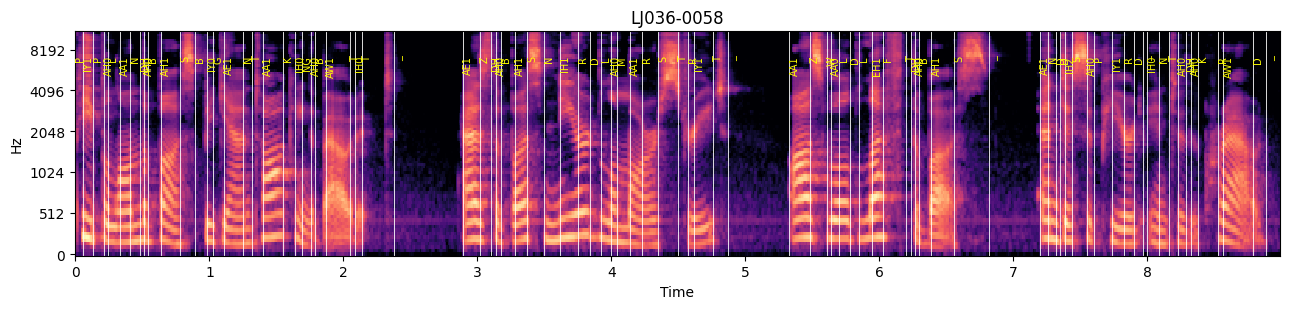

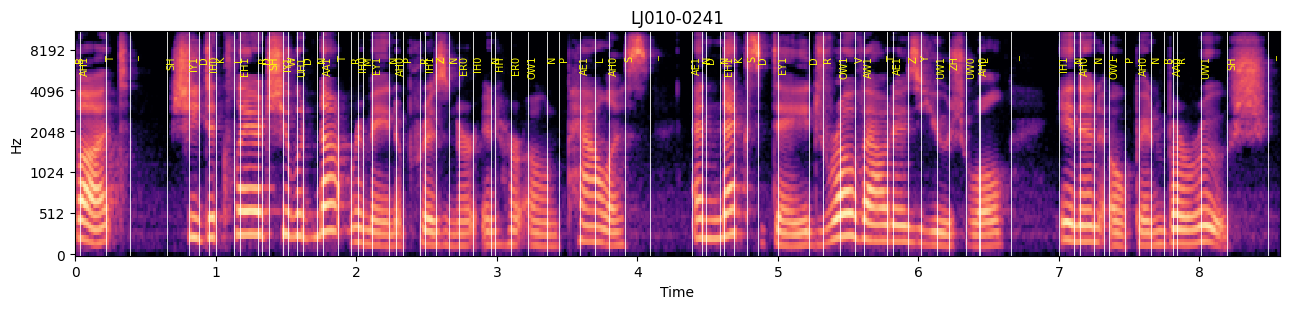

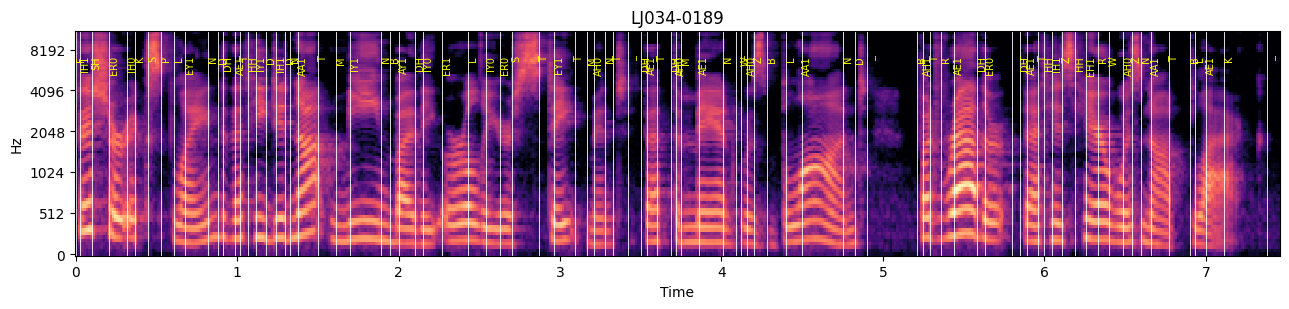

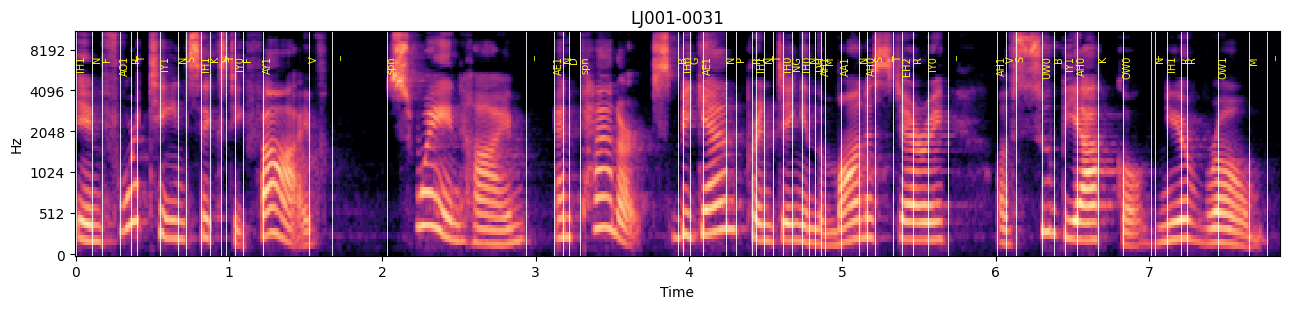

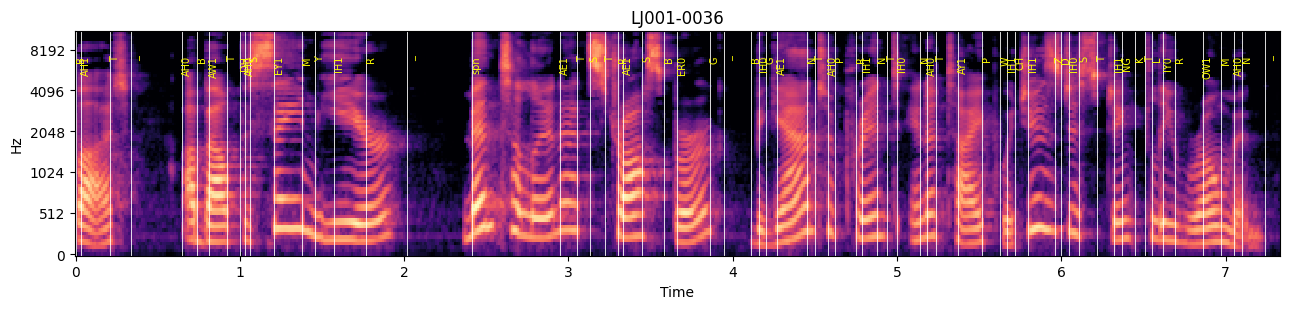

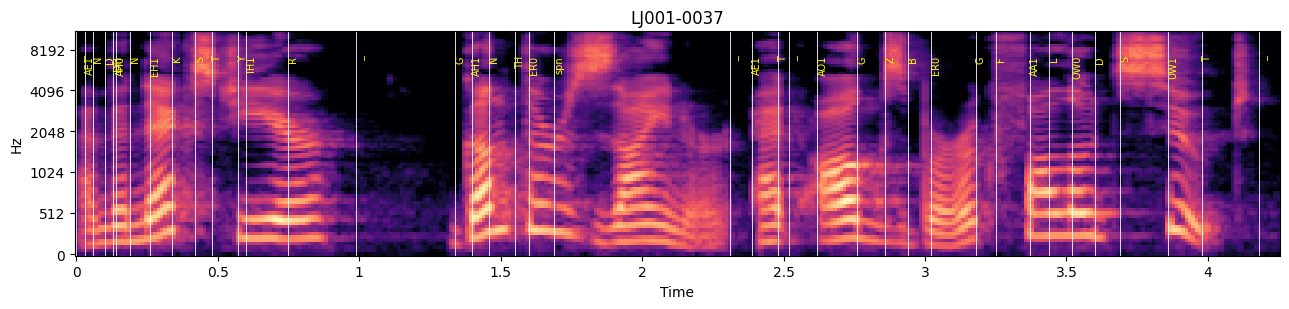

In [88]:
# ---- Spot-check: look at 3 random clips and 3 flagged ones (boundaries drawn on the mel spectrogram), and LISTEN to them
import librosa, librosa.display, matplotlib.pyplot as plt, IPython.display as ipd
def show(cid):
    y, sr = librosa.load(os.path.join(RAW, 'wavs', cid + '.wav'), sr=A['sample_rate'])
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_fft=A['n_fft'], hop_length=A['hop_length'], n_mels=A['n_mels']), ref=np.max)
    d = al[al.utt_id == cid]
    fig, ax = plt.subplots(figsize=(13, 3.2))
    librosa.display.specshow(mel, sr=sr, hop_length=A['hop_length'], x_axis='time', y_axis='mel', ax=ax)
    for _, r in d.iterrows():
        ax.axvline(r.start_s, color='w', lw=0.6)
        ax.text(r.start_s, 7500, r.label if r.label else '_', color='yellow', fontsize=7, rotation=90, va='top')
    ax.set_title(cid); plt.tight_layout(); plt.show()
    ipd.display(ipd.Audio(y, rate=sr))
rng = np.random.RandomState(0)
for cid in list(rng.choice(qa[~qa.exclude].utt_id, 3, replace=False)) + list(qa[qa.exclude].utt_id.head(3)):
    show(cid)